# Stage 1 — EDA

## Step 1: Total sales over time (aggregate level)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the processed long-format table built in Stage 0
BASE_DIR = Path("/Users/asadkhan.pathan/Documents/New project/m5 forecasting ")
df = pd.read_parquet(BASE_DIR / "data" / "processed" / "sales_long.parquet")

print(df.shape)
print(df["date"].min(), "to", df["date"].max())
df.head()

(59181090, 22)
2011-01-29 00:00:00 to 2016-05-22 00:00:00


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,1,2011,NaN,NaN,NaN,NaN,0,0,0,NaN


In [1]:
df["cat_id"].unique()

NameError: name 'df' is not defined

### Aggregate: total sales per day, summed across ALL 30,490 series

We're zooming all the way out first — before drilling into individual
stores/items, we want to see the big-picture trend and seasonality that
only becomes visible once daily noise cancels out across series.

In [2]:
# groupby("date") collapses all 30,490 series into one number per day.
# observed=True is a good habit when grouping on category dtype columns.
daily_total = df.groupby("date", observed=True)["sales"].sum().reset_index()

print(daily_total.shape)  # expect one row per unique day
daily_total.head()

(1941, 2)


,date,sales
0,2011-01-29,32631
1,2011-01-30,31749
2,2011-01-31,23783
3,2011-02-01,25412
4,2011-02-02,19146


### Plot

Watch for: overall trend (growing/flat/declining?), a repeating weekly
wiggle, and any hard drops (e.g. Walmart stores are closed on Christmas
Day every year — that shows up as a true zero, not just "low demand").

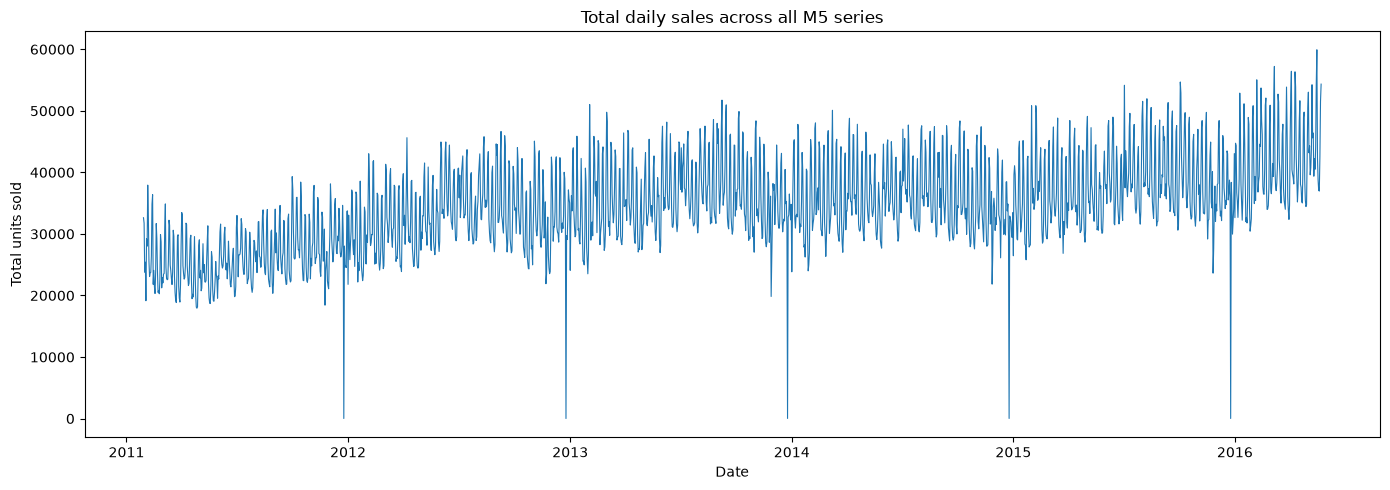

In [3]:
plt.figure(figsize=(14, 5))
plt.plot(daily_total["date"], daily_total["sales"], linewidth=0.8)
plt.title("Total daily sales across all M5 series")
plt.xlabel("Date")
plt.ylabel("Total units sold")
plt.tight_layout()
plt.show()

## Step 2: Sales by state

Splitting the same total into 3 lines (CA, TX, WI). We care about
*shape* (trend direction, seasonality pattern) more than absolute level —
CA has more stores than TX/WI so its line will naturally sit higher,
which doesn't by itself mean anything interesting.

In [6]:
# Group by state_id AND date together, so we get one sales total per
# (state, day) pair instead of collapsing states into one number.
by_state = df.groupby(["state_id", "date"], observed=True)["sales"].sum().reset_index()

print(by_state.shape)  # expect 3 states * ~1941 days
by_state.sample(3)

(5823, 3)


,state_id,date,sales
4621,WI,2013-02-06,11236
2797,TX,2013-06-03,11180
2989,TX,2013-12-12,8769


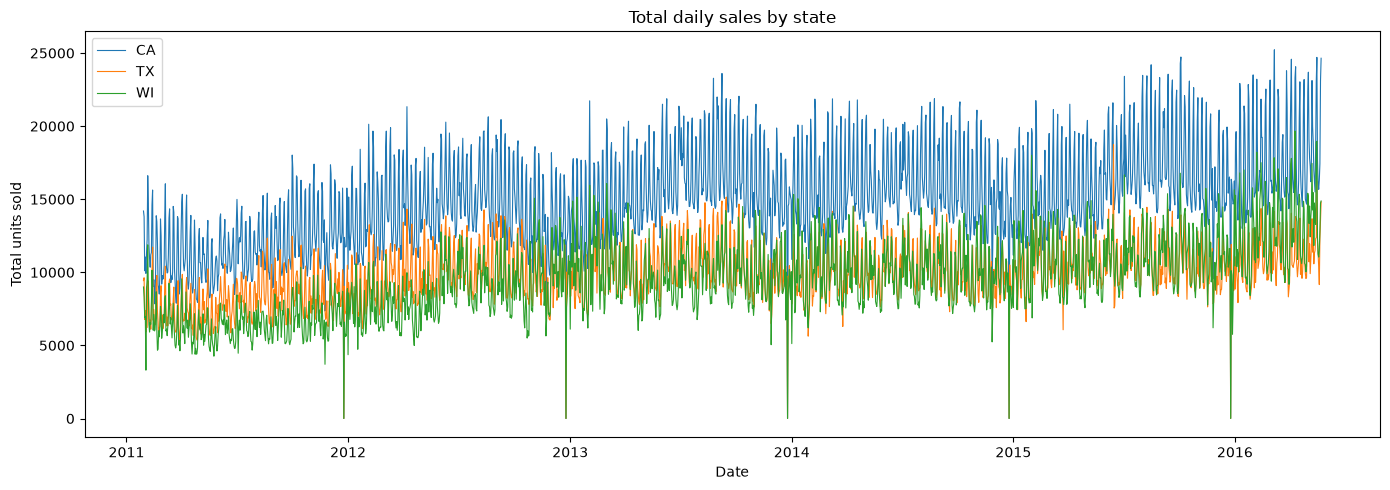

In [7]:
plt.figure(figsize=(14, 5))
for state, group in by_state.groupby("state_id", observed=True):
    plt.plot(group["date"], group["sales"], linewidth=0.8, label=state)

plt.title("Total daily sales by state")
plt.xlabel("Date")
plt.ylabel("Total units sold")
plt.legend()
plt.tight_layout()
plt.show()

## Step 3: Sales by store (small multiples)

With 10 stores, one overlaid line plot becomes unreadable (too many
colors). Instead we use small multiples — one subplot per store, same
y-axis scale — so shapes are easy to compare side by side.


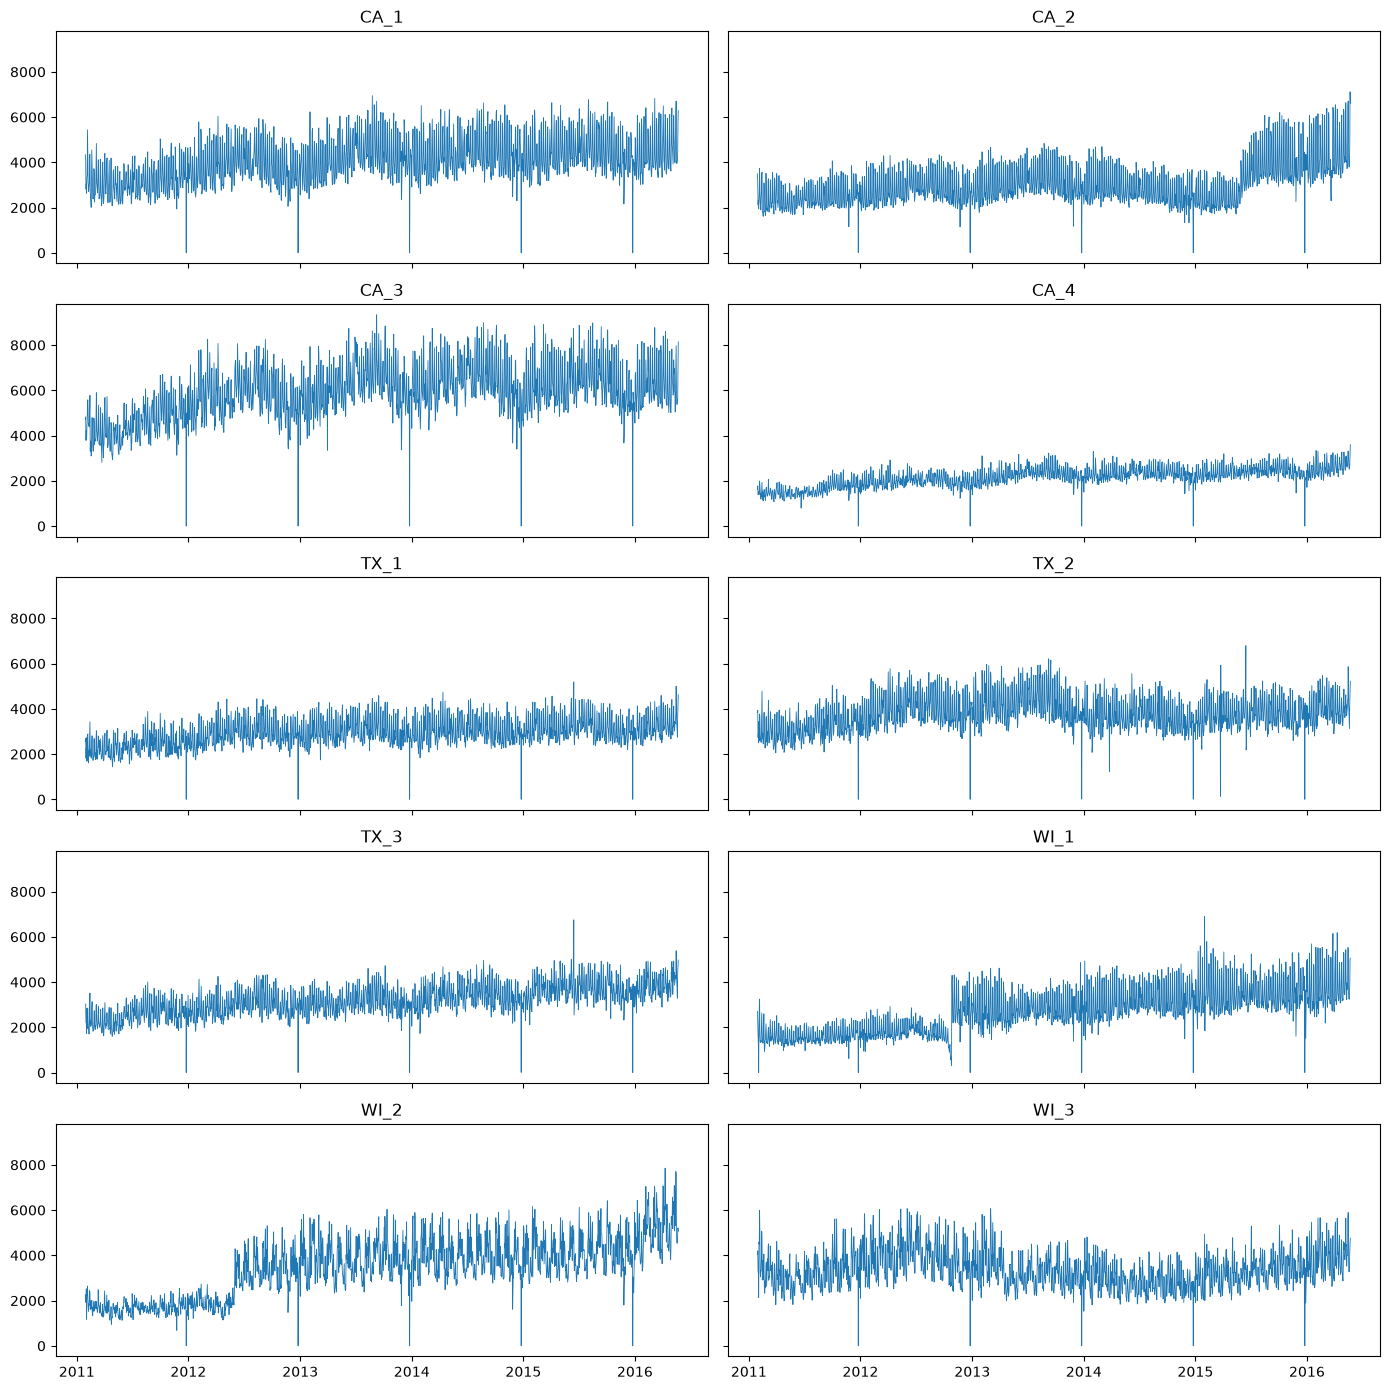

In [9]:
by_store = df.groupby(["store_id", "date"], observed=True)["sales"].sum().reset_index()

stores = sorted(by_store["store_id"].unique())
fig, axes = plt.subplots(5, 2, figsize=(14, 14), sharex=True, sharey=True)

for ax, store in zip(axes.flat, stores):
    group = by_store[by_store["store_id"] == store]
    ax.plot(group["date"], group["sales"], linewidth=0.6)
    ax.set_title(store)

plt.tight_layout()
plt.show()


## Step 4: Sales by category

Categories represent fundamentally different product types, so unlike
store/state we might expect genuinely different demand shapes here, not
just a scaled copy. FOODS is also the only category eligible for SNAP
benefits — worth keeping in mind for later stages.


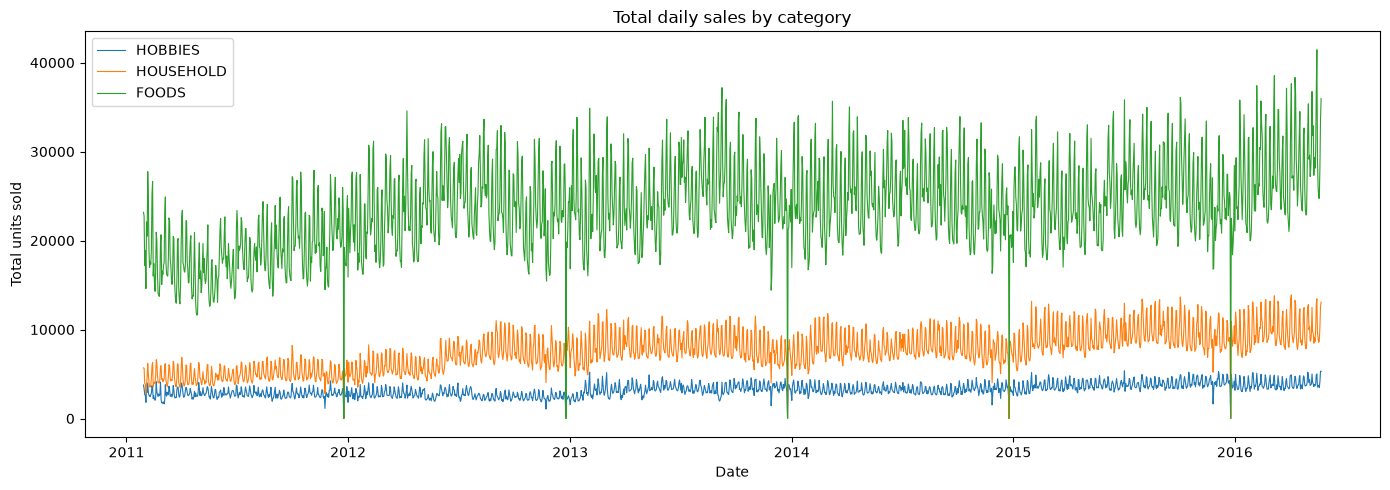

In [14]:
by_cat = df.groupby(["cat_id", "date"], observed=True)["sales"].sum().reset_index()

plt.figure(figsize=(14, 5))
for cat, group in by_cat.groupby("cat_id", observed=True):
    plt.plot(group["date"], group["sales"], linewidth=0.8, label=cat)

plt.title("Total daily sales by category")
plt.xlabel("Date")
plt.ylabel("Total units sold")
plt.legend()
plt.tight_layout()
plt.show()


## Step 5: Sales by department

Each category splits into departments (FOODS_1/2/3, HOUSEHOLD_1/2,
HOBBIES_1/2). Checking whether departments within the same category
behave similarly, or whether category-level patterns are hiding
different sub-behavior.


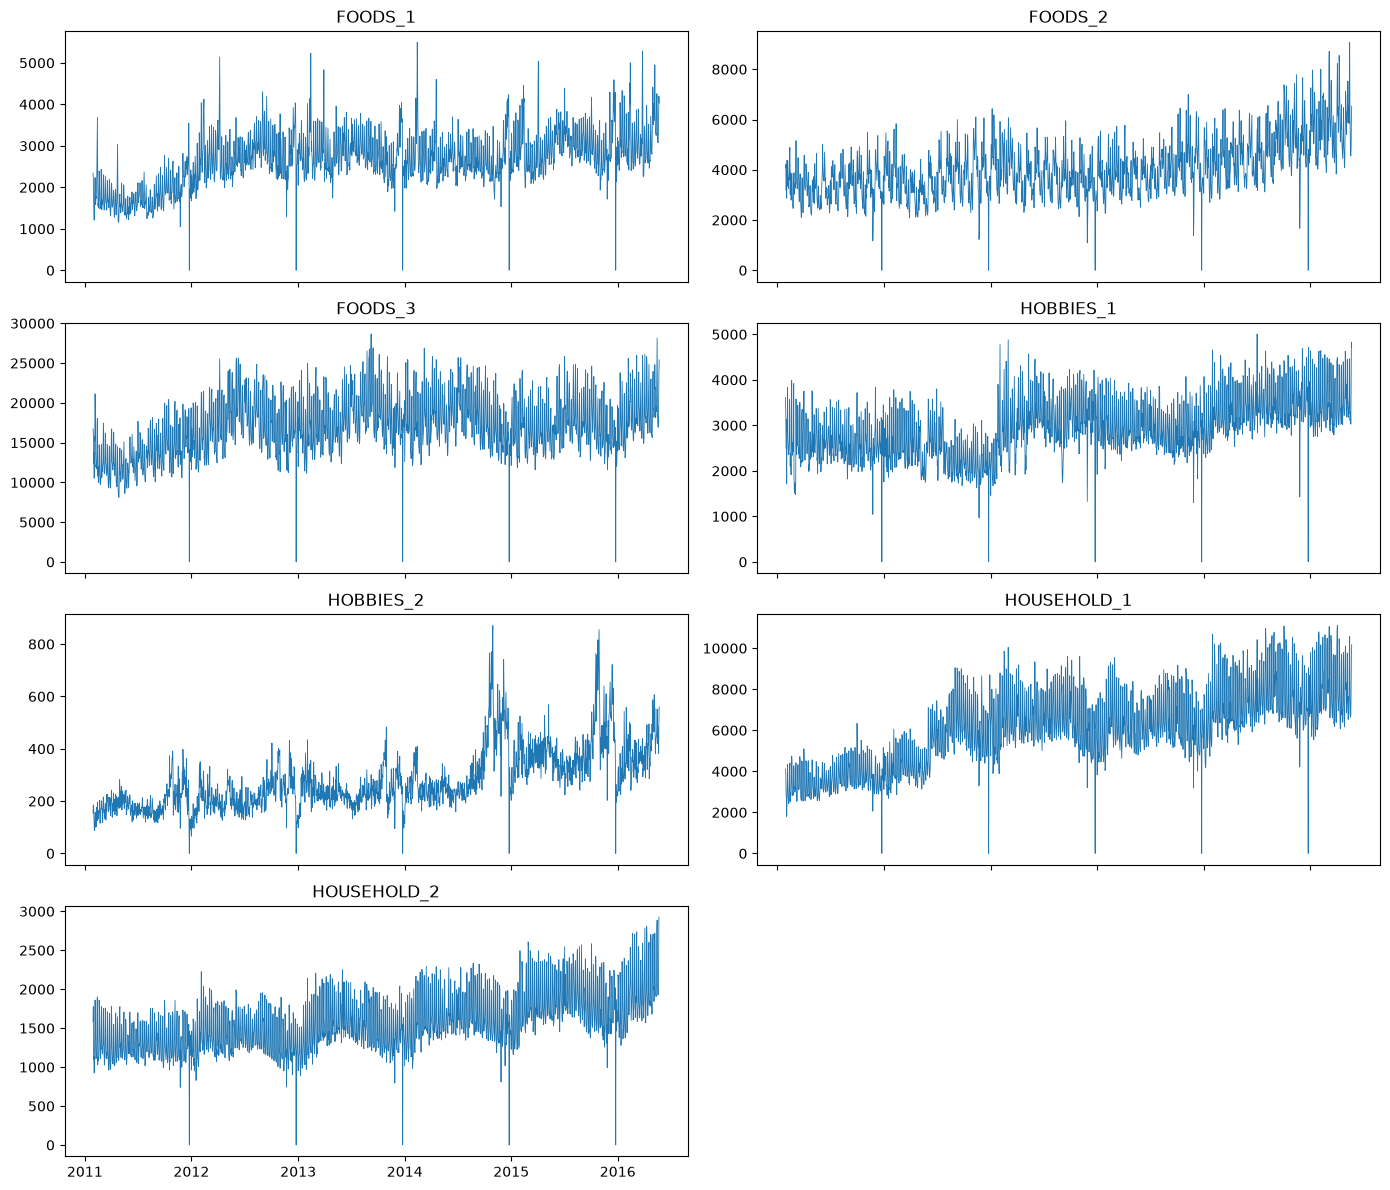

In [17]:
by_dept = df.groupby(["dept_id", "date"], observed=True)["sales"].sum().reset_index()

depts = sorted(by_dept["dept_id"].unique())
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)

for ax, dept in zip(axes.flat, depts):
    group = by_dept[by_dept["dept_id"] == dept]
    ax.plot(group["date"], group["sales"], linewidth=0.6)
    ax.set_title(dept)

# 7 depts in an 8-slot (4x2) grid leaves one empty subplot — hide it
for ax in axes.flat[len(depts):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Step 6: Individual item-level series (intermittency)

Everything so far has been aggregated (state/store/category/dept), which
smooths out noise. At the individual item-store level, M5 is known for
intermittent demand — long stretches of zero sales punctuated by spikes.
Aggregation hides this; we need to look at raw series to see it.


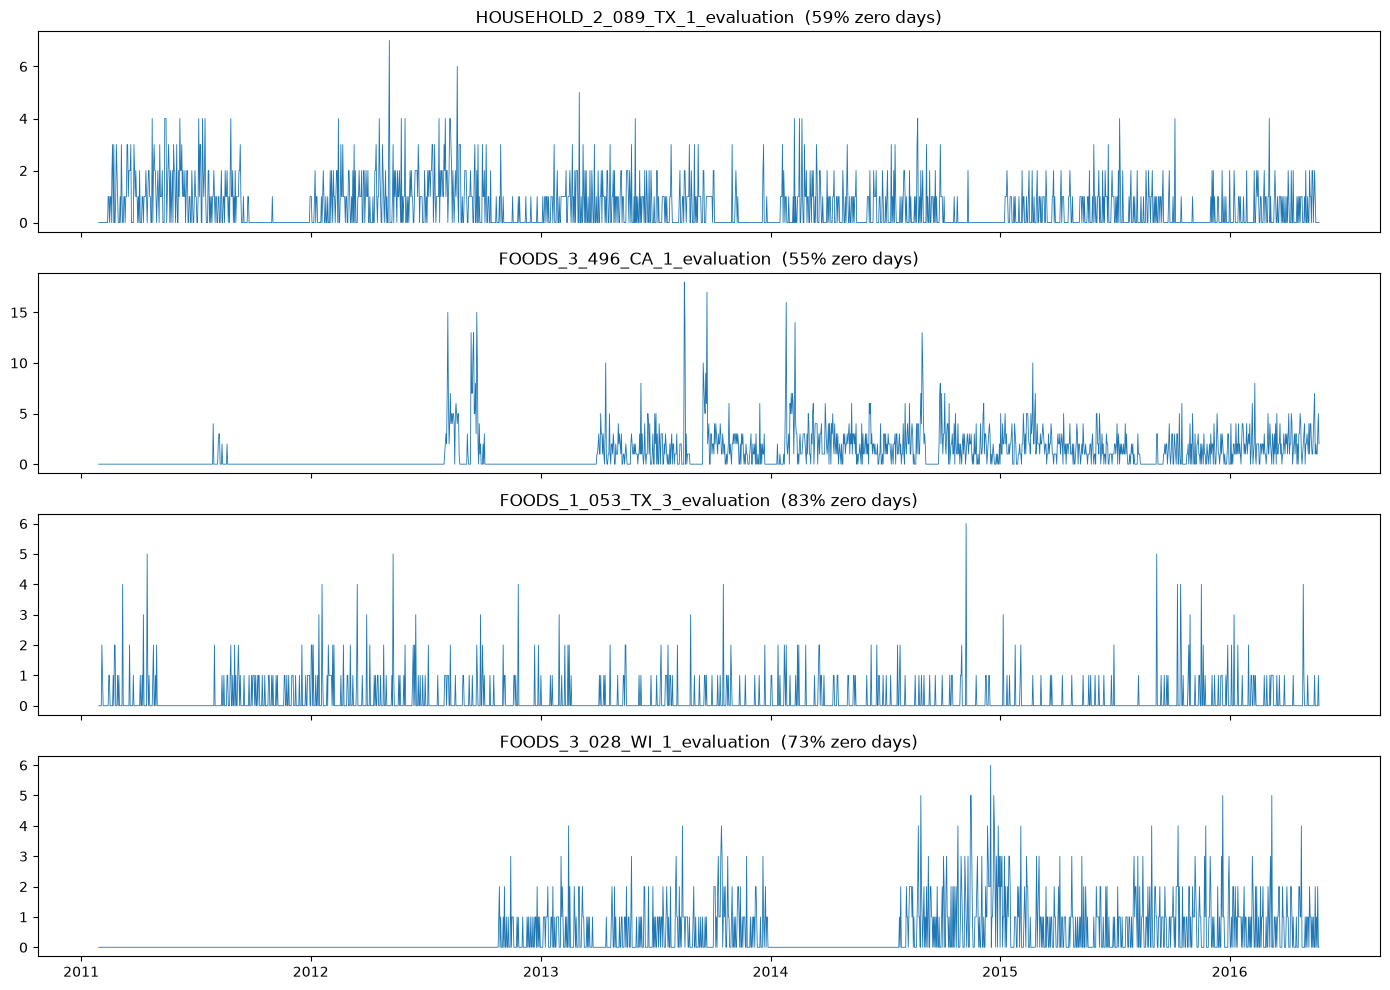

In [18]:
import numpy as np

# Pick 4 random item-store series to look at individually
rng = np.random.default_rng(42)
sample_ids = rng.choice(df["id"].unique(), size=4, replace=False)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, series_id in zip(axes, sample_ids):
    s = df[df["id"] == series_id].sort_values("date")
    ax.plot(s["date"], s["sales"], linewidth=0.6)
    zero_pct = (s["sales"] == 0).mean() * 100
    ax.set_title(f"{series_id}  ({zero_pct:.0f}% zero days)")

plt.tight_layout()
plt.show()


## Step 7: Zero-sales frequency across all series

Instead of eyeballing a handful of series, compute % of zero-sales days
for every one of the 30,490 series and plot the distribution. This tells
us how widespread intermittency really is, not just that it exists.


count    30490.000000
mean        67.997766
std         22.340622
min          0.154560
25%         53.477589
50%         73.312725
75%         86.501803
max         99.381762
Name: sales, dtype: float64


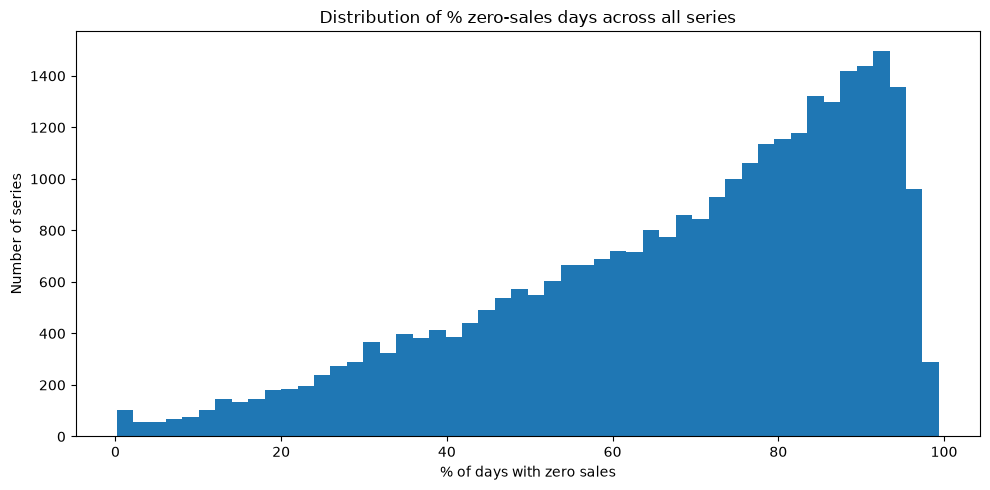

In [19]:
zero_pct_per_series = df.groupby("id", observed=True)["sales"].apply(lambda s: (s == 0).mean() * 100)

print(zero_pct_per_series.describe())

plt.figure(figsize=(10, 5))
plt.hist(zero_pct_per_series, bins=50)
plt.title("Distribution of % zero-sales days across all series")
plt.xlabel("% of days with zero sales")
plt.ylabel("Number of series")
plt.tight_layout()
plt.show()


## Step 8: Weekly seasonality

Quantifying the weekly wiggle we've seen visually since Step 1 — boxplot
of total daily sales grouped by day of week, across all ~280 weeks of
history. Shows both the typical level per weekday and how consistent
that pattern is.


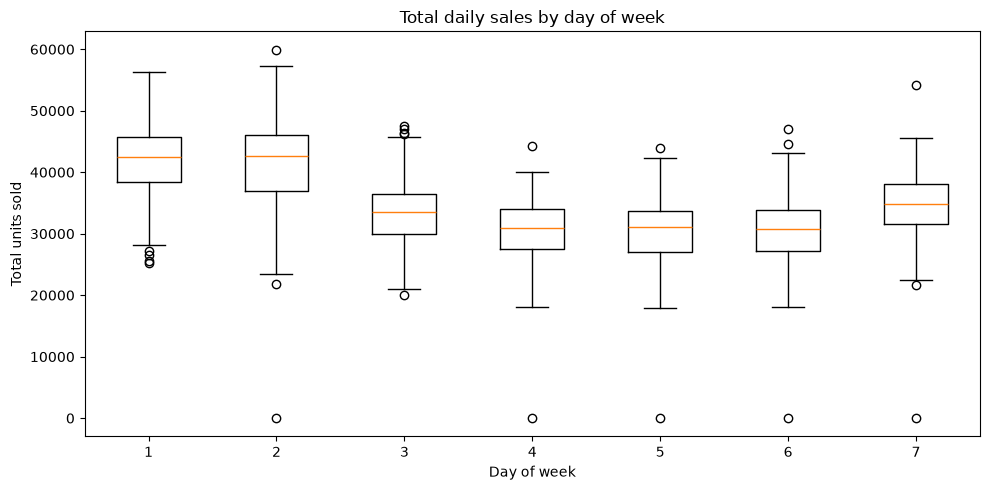

In [23]:
# Aggregate total sales per date, keeping wday (day-of-week number) alongside.
# wday is deterministic per date, so grouping by both together doesn't
# split anything further than grouping by date alone.
daily_wday = df.groupby(["date", "wday"], observed=True)["sales"].sum().reset_index()

# wday runs 1-7; grab the corresponding weekday names for axis labels.
wday_labels = (
    df[["wday", "weekday"]]
    .drop_duplicates()
    .sort_values("wday")["weekday"]
    .tolist()
)

data_by_wday = [daily_wday[daily_wday["wday"] == w]["sales"].values for w in sorted(daily_wday["wday"].unique())]

plt.figure(figsize=(10, 5))
plt.boxplot(data_by_wday, label=wday_labels)
plt.title("Total daily sales by day of week")
plt.xlabel("Day of week")
plt.ylabel("Total units sold")
plt.tight_layout()
plt.show()


## Step 9: SNAP effect

SNAP benefits apply per-state, per-day, and should only meaningfully
affect FOODS sales. Checking FOODS vs non-FOODS categories confirms
both the real effect and that we understand SNAP's scope correctly.


In [24]:
# Each row's state determines which snap_<state> column actually applies to it.
snap_by_state = {"CA": "snap_CA", "TX": "snap_TX", "WI": "snap_WI"}
df["snap_active"] = df.apply(lambda r: r[snap_by_state[r["state_id"]]], axis=1)


           non-SNAP day  SNAP day  % difference
cat_id                                         
HOBBIES        0.564476  0.578371      2.461512
HOUSEHOLD      0.718150  0.743467      3.525331
FOODS          1.557814  1.826562     17.251658


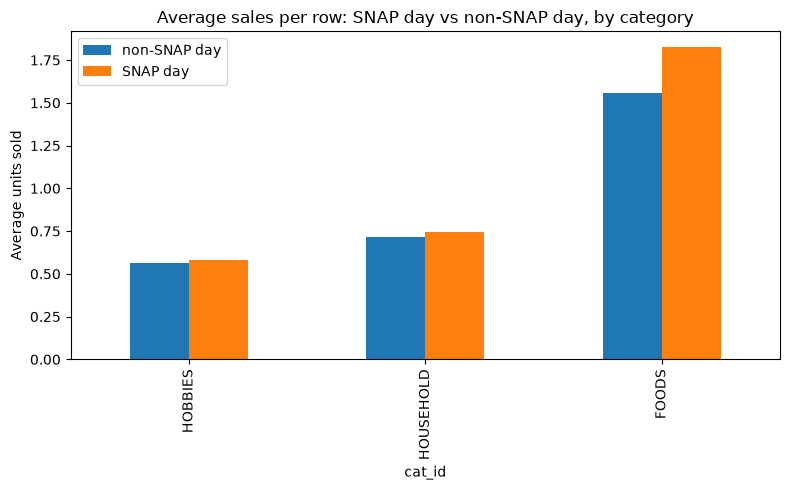

In [25]:
snap_effect = df.groupby(["cat_id", "snap_active"], observed=True)["sales"].mean().unstack()
snap_effect.columns = ["non-SNAP day", "SNAP day"]
snap_effect["% difference"] = (snap_effect["SNAP day"] / snap_effect["non-SNAP day"] - 1) * 100

print(snap_effect)

snap_effect[["non-SNAP day", "SNAP day"]].plot(kind="bar", figsize=(8, 5))
plt.title("Average sales per row: SNAP day vs non-SNAP day, by category")
plt.ylabel("Average units sold")
plt.tight_layout()
plt.show()
